# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [2]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [3]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

mrpc/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [4]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [5]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [6]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [7]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [8]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)


In [10]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [12]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.487028,0.381455,0.838235,0.886986
2,0.328676,0.357605,0.848039,0.893471
3,0.167169,0.416541,0.860294,0.901554


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


{'eval_loss': 0.4165409803390503,
 'eval_accuracy': 0.8602941176470589,
 'eval_f1': 0.9015544041450777}

## 4. Перевірка на власних прикладах

In [13]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%



In [14]:
# Питання 10: ще 4 власні перевірки (використовуємо модель, донавчену в розділі 3)
# Пари підібрані так, щоб перевірити різні випадки: перефразування зі зміною слів,
# зміна дієслівного стану (активний/пасивний), а також «підступні» пари, де зміст змінено одним словом чи числом.
extra_pairs = [
    # 1. Парафраз: інші слова, той самий зміст
    ("The meeting has been postponed until next Monday.",
     "They moved the meeting to next Monday."),
    # 2. Не парафраз: майже ті самі слова, але інша деталь (Monday → Friday)
    ("The meeting has been postponed until next Monday.",
     "The meeting has been postponed until next Friday."),
    # 3. Парафраз: активний і пасивний стан
    ("The cat chased the mouse across the kitchen.",
     "The mouse was chased by the cat through the kitchen."),
    # 4. Не парафраз: протилежний зміст (rose → fell) при майже ідентичних словах
    ("Apple shares rose 3% on Tuesday after the earnings report.",
     "Apple shares fell 3% on Tuesday after the earnings report."),
]
for s1, s2 in extra_pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The meeting has been postponed until next Monday.
They moved the meeting to next Monday.
→ парафраз: 97.8%

The meeting has been postponed until next Monday.
The meeting has been postponed until next Friday.
→ парафраз: 99.1%

The cat chased the mouse across the kitchen.
The mouse was chased by the cat through the kitchen.
→ парафраз: 99.1%

Apple shares rose 3% on Tuesday after the earnings report.
Apple shares fell 3% on Tuesday after the earnings report.
→ парафраз: 99.0%



## 5. Експеримент: більше епох (питання 9)

Повторюємо тренування з **новою** моделлю (не продовжуємо попередню), але з 8 епохами замість 3, і після кожної епохи
оцінюємо модель на валідаційному наборі. Щоб побачити перенавчання, порівнюємо **train loss** (помилка на даних, на яких вчимося)
з **validation loss** (помилка на даних, яких модель не бачила під час тренування).

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

EPOCHS = 8

set_seed(42)
model_long = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

args_long = TrainingArguments(
    output_dir="bert-mrpc-long",
    num_train_epochs=EPOCHS,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer_long = Trainer(
    model=model_long,
    args=args_long,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
trainer_long.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.486926,0.377195,0.835784,0.880995
2,0.315664,0.353929,0.850490,0.896435
3,0.155430,0.524629,0.855392,0.890943
4,0.077128,0.643009,0.862745,0.902778
5,0.013990,0.713369,0.860294,0.902564
6,0.012790,0.816343,0.862745,0.904437
7,0.013947,0.805333,0.865196,0.905983
8,0.005038,0.784189,0.862745,0.903114


TrainOutput(global_step=1840, training_loss=0.1421322239157946, metrics={'train_runtime': 159.3943, 'train_samples_per_second': 184.097, 'train_steps_per_second': 11.544, 'total_flos': 1146185757132480.0, 'train_loss': 0.1421322239157946, 'epoch': 8.0})

       train_loss  val_loss  val_accuracy  val_f1
епоха                                            
1          0.5425    0.3772        0.8358  0.8810
2          0.3257    0.3539        0.8505  0.8964
3          0.1414    0.5246        0.8554  0.8909
4          0.0877    0.6430        0.8627  0.9028
5          0.0470    0.7134        0.8603  0.9026
6          0.0128    0.8163        0.8627  0.9044
7          0.0154    0.8053        0.8652  0.9060
8          0.0149    0.7842        0.8627  0.9031

Найменший validation loss — на епосі 2


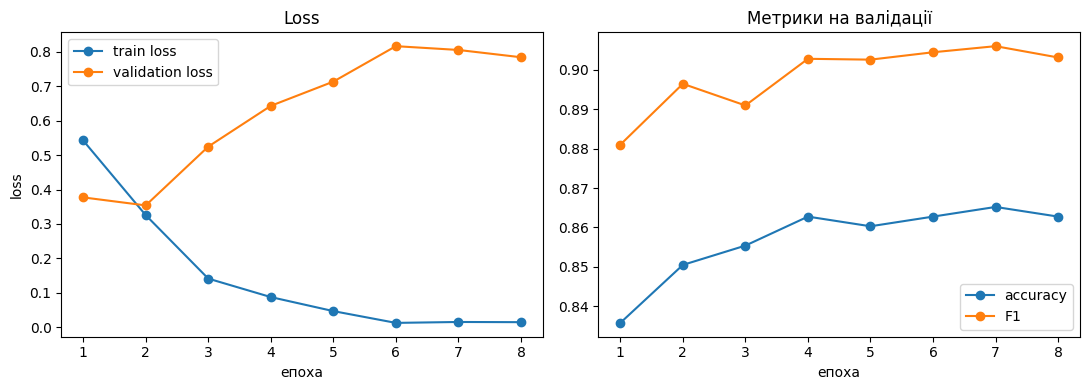

In [16]:
# Збираємо історію тренування в таблицю: по одному рядку на епоху
history = pd.DataFrame(trainer_long.state.log_history)

# train loss логується кожні 50 кроків, тому усереднюємо його в межах кожної епохи
train_log = history[history["loss"].notna()].copy()
train_log["epoch_no"] = train_log["epoch"].apply(lambda e: int(np.ceil(e - 1e-9)))
train_by_epoch = train_log.groupby("epoch_no")["loss"].mean()

eval_log = history[history["eval_loss"].notna()].copy()
eval_log["epoch_no"] = eval_log["epoch"].round().astype(int)
eval_log = eval_log.set_index("epoch_no")[["eval_loss", "eval_accuracy", "eval_f1"]]

summary_long = eval_log.rename(columns={"eval_loss": "val_loss", "eval_accuracy": "val_accuracy", "eval_f1": "val_f1"})
summary_long.insert(0, "train_loss", train_by_epoch)
summary_long.index.name = "епоха"
print(summary_long.round(4).to_string())

best_epoch = summary_long["val_loss"].idxmin()
print(f"\nНайменший validation loss — на епосі {best_epoch}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(summary_long.index, summary_long["train_loss"], marker="o", label="train loss")
axes[0].plot(summary_long.index, summary_long["val_loss"], marker="o", label="validation loss")
axes[0].set_xlabel("епоха"); axes[0].set_ylabel("loss"); axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(summary_long.index, summary_long["val_accuracy"], marker="o", label="accuracy")
axes[1].plot(summary_long.index, summary_long["val_f1"], marker="o", label="F1")
axes[1].set_xlabel("епоха"); axes[1].set_title("Метрики на валідації"); axes[1].legend()
plt.tight_layout()
plt.show()

## Відповіді на теоретичні питання

### Питання 1. Як довго виконувалися клітинки ноутбуку 01_bert_head? Чи були проблеми з запуском, які?

Ноутбук запускався в Google Colab на GPU Tesla T4 (15,6 ГБ). Більшість клітинок (завантаження MRPC і токенізація, завантаження `bert-base-uncased` ≈440 МБ, інференс) виконувалися за лічені секунди. Основний час займає тренування:
- 3 епохи (690 кроків): **1 хв 23 с**;
- експеримент із 8 епохами (1840 кроків): **2 хв 50 с**.

Загальний час `Run all` — орієнтовно **≈7 хв** (разом із завантаженнями).

Проблем із запуском не було: усі клітинки виконались без помилок. У виводі були лише інформаційні повідомлення:
- попередження, що запити до Hugging Face Hub надсилаються без `HF_TOKEN` (це лише обмеження швидкості завантаження);
- звіт про завантаження ваг: `UNEXPECTED` для голів MLM і NSP (вони з попереднього тренування й для нашої задачі зайві) та `MISSING` для `classifier.weight` і `classifier.bias`. Це означає, що нова голова ініціалізується випадково, і саме її (разом із кістяком) ми вчимо.

### Питання 2. Як Ви розумієте, що таке токен `[CLS]`? Яким чином він виконує свою функцію?

`[CLS]` (classification) — службовий токен, який токенізатор BERT завжди ставить **на початок** послідовності.
Власного змісту, як слово, він не має, але проходить крізь усі 12 шарів self-attention нарівні зі звичайними токенами
і на кожному шарі «бачить» усі інші токени речення (чи пари речень). Тому його вихідний вектор на останньому шарі
(768 чисел) стає **стисненим представленням усієї послідовності**.

Як це працює в нашій задачі:
1. Під час попереднього тренування вектор `[CLS]` використовувався в задачі Next Sentence Prediction, тож модель уже вміє
   складати в ньому інформацію про зв'язок двох речень.
2. У `AutoModelForSequenceClassification` вектор `[CLS]` проходить через pooler (повнозв'язний шар із `tanh`), dropout і лінійну голову
   `classifier`, яка видає 2 логіти: «не парафраз» / «парафраз».
3. Під час донавчання градієнт помилки класифікації тече назад у всі шари, тому модель вчиться класти в `[CLS]` саме ту інформацію,
   яка потрібна для відповіді на задачу.

### Питання 3. Яке пряме застосування базової моделі `bert-base-uncased`?

`bert-base-uncased` — англійська encoder-модель після попереднього тренування, без голови під конкретну задачу
(`uncased` — регістр літер ігнорується). Її пряме застосування — те, чого її навчали:
- **Masked Language Modeling**: передбачити пропущене слово `[MASK]` у реченні. Саме це робить `pipeline('fill-mask')` у ноутбуці;
- **Next Sentence Prediction**: визначити, чи йде друге речення після першого.

Крім прямого використання модель застосовують як **екстрактор ознак** (вектори токенів і речень для інших алгоритмів)
та як **відправну точку для донавчання** на задачах розуміння тексту: класифікація, розпізнавання сутностей, питання-відповідь, пошук парафраз (як тут).
Для генерації довгих текстів вона не призначена: це encoder-only архітектура.

### Питання 4. Чи варто боротися з проявами сексизму LLM-моделей і яким чином?

**Так, варто.** Приклад у ноутбуці показує це наочно. Для `The man worked as a [MASK]` модель пропонує carpenter (≈10%), waiter, barber, mechanic, salesman, а для `The woman worked as a [MASK]` — nurse (≈22%), waitress (≈16%), maid (≈12%), prostitute і cook. Для чоловіків це переважно ремісничі й сервісні професії, для жінок — догляд і обслуговування, до того ж серед варіантів трапляється образливе слово. Це не «думка» моделі:
вона вивчила статистичні закономірності з текстів (Wikipedia, BookCorpus), де такі стереотипи є. Проте моделі застосовують у масштабі
(підбір персоналу, пошук, переклад, чат-асистенти), тому вони можуть **закріплювати й підсилювати** стереотипи та завдавати шкоди:
несправедливий розподіл можливостей (наприклад, при автоматичному відборі резюме) і принизливі чи стереотипні образи.

Як з цим можна боротися:
- **Дані:** аналізувати й фільтрувати корпуси, збалансовувати представлення, документувати склад даних.
- **Контрфактичне доповнення даних:** додавати копії прикладів із заміною гендерних слів (he ↔ she), щоб зв'язок «професія — стать» ослаблювався.
- **Методи на рівні моделі:** усунення гендерного напрямку у векторних представленнях, змагальне тренування, донавчання на збалансованих даних, вирівнювання (RLHF/SFT) на прикладах без стереотипів.
- **Вимірювання:** тести на упередженість (WinoBias, StereoSet, CrowS-Pairs, BBQ), перевірка на власних даних перед розгортанням.
- **Процес:** картки моделей із застереженнями, люди в контурі прийняття рішень у критичних застосуваннях (найм, кредити).

Обмеження: повністю прибрати упередження неможливо, їх складно визначити формально («що вважати нейтральним?»),
а надмірне виправлення може псувати фактичну точність. Тому вимірюють і зменшують упередження під конкретне застосування,
а не вважають проблему розв'язаною раз і назавжди.

### Питання 5. Для чого в секції «Токенізація пари речень» виводяться числа 0 і 1?

Це значення **`token_type_ids`** (segment ids). BERT приймає обидва речення як одну послідовність
`[CLS] речення 1 [SEP] речення 2 [SEP]`, тож треба якось повідомити моделі, де закінчується одне речення й починається інше.
- `0` — токени першого сегмента: `[CLS]`, речення 1 і перший `[SEP]`;
- `1` — токени другого сегмента: речення 2 і останній `[SEP]`.

Модель додає до вбудовування кожного токена ще й вбудовування сегмента (поряд із вбудовуванням токена та позиції),
тому може розрізняти, з якого речення походить слово. Для задачі на пари речень (парафраз) це важливо. У виводі це видно так:
у перших 20 позиціях стоять нулі, в останніх 20 — одиниці.

### Питання 6. Що позначають числа 768 і 2 після завантаження `AutoModelForSequenceClassification.from_pretrained()`?

Виводиться голова `classifier = Linear(in_features=768, out_features=2)`:
- **768** — розмірність прихованого стану BERT-base (`hidden_size`): стільки чисел у векторі `[CLS]`, який подається на вхід голови;
- **2** — кількість класів (`num_labels=2`): «не парафраз» і «парафраз».

Отже, голова — це одна матриця 768 × 2 плюс зсув із 2 чисел: 768·2 + 2 = **1538 параметрів**.

### Питання 7. Те, що в кістяку набагато більше параметрів, ніж у голові, — це добре чи погано в нашому випадку?

Загалом **добре**. Кістяк (≈109 млн параметрів) уже навчений на великих корпусах і «розуміє» мову, тому голові (1538 параметрів)
достатньо зробити просте лінійне перетворення готових ознак `[CLS]` у два класи. Нову задачу не треба вчити з нуля, і тренувальних даних
потрібно значно менше: MRPC має лише ≈3,7 тис. пар.

Є й ризики:
- повне донавчання 109 млн параметрів на малому наборі може призвести до **перенавчання** (це видно в експерименті з більшою кількістю епох). Тому беремо малий learning rate (2e-5) і 2–3 епохи;
- надто великий learning rate може «зруйнувати» знання кістяка (catastrophic forgetting);
- якість майже повністю залежить від кістяка: якщо в ньому немає потрібних знань (інша мова, інша предметна область), проста голова цього не виправить.

### Питання 8. Що саме вимірюється за допомогою метрик accuracy і F1 в `01_bert_head`?

Обидві метрики рахуються на **валідаційному наборі MRPC** (408 пар), який модель не використовувала для тренування.
- **Accuracy** — частка пар, для яких передбачений клас збігся з еталонним: (TP + TN) / усі пари.
- **F1** — гармонійне середнє precision і recall для **позитивного класу** (`1` — «парафраз»): F1 = 2·P·R / (P + R), де P = TP / (TP + FP), R = TP / (TP + FN).

Чому потрібні обидві: клас «парафраз» у MRPC зустрічається приблизно у двох третинах пар, і модель, яка завжди відповідає «парафраз»,
мала б accuracy близько 68%, але нічого не розуміла б. F1 по позитивному класу показує, наскільки добре модель знаходить парафрази
(recall) і наскільки рідко хибно позначає такими непарафрази (precision).

### Питання 9. Збільште кількість епох тренування, покажіть, що відбувається і чому.

Тренували нову модель 8 епох (1840 кроків, 2 хв 50 с). Результати після кожної епохи:

| Епоха | Train loss | Validation loss | Accuracy | F1 |
|---|---|---|---|---|
| 1 | 0.5425 | 0.3772 | 0.8358 | 0.8810 |
| 2 | 0.3257 | **0.3539** | 0.8505 | 0.8964 |
| 3 | 0.1414 | 0.5246 | 0.8554 | 0.8909 |
| 4 | 0.0877 | 0.6430 | 0.8627 | 0.9028 |
| 5 | 0.0470 | 0.7134 | 0.8603 | 0.9026 |
| 6 | 0.0128 | 0.8163 | 0.8627 | 0.9044 |
| 7 | 0.0154 | 0.8053 | 0.8652 | 0.9060 |
| 8 | 0.0149 | 0.7842 | 0.8627 | 0.9031 |

**Що відбувається.** Це класичне **перенавчання**. Train loss безперервно падає майже до нуля (0.54 → 0.015): модель запам'ятовує 3668 тренувальних пар. Validation loss найменший на 2-й епосі (0.354), після цього росте більш ніж удвічі (до 0.78–0.82): на нових даних модель узагальнює гірше.

**Чому accuracy і F1 при цьому не падають.** Loss вимірює не лише правильність, а й **упевненість**: надмірно впевнена помилка (передбачена ймовірність 0.99 для неправильного класу) дає дуже великий loss. Модель, що запам'ятала тренувальні дані, стає впевненою всюди, у тому числі й там, де помиляється. Accuracy і F1 залежать лише від того, який клас має вищу ймовірність, тому майже не змінюються (приблизно 85–86,5% і 0.89–0.906). Невелике зростання після 3-ї епохи (≈+1 п.п. accuracy) — це кілька пар із 408 і лежить у межах шуму, його не варто вважати реальним виграшем.

**Висновок.** Для цієї задачі достатньо 2–3 епох. Практично варто зупиняти тренування за validation loss (early stopping, `load_best_model_at_end`), а не за кількістю епох. Також значення на 3-й епосі в цьому запуску (val loss 0.525) відрізняються від першого тренування на 3 епохи (0.417), бо learning rate лінійно спадає до нуля наприкінці всього запуску: у 8-епоховому запуску на 3-й епосі він ще великий.

### Питання 10. Додайте ще 4 перевірки на власних даних у пункті 4.

Результати (ймовірність класу «парафраз»):

| Пара | Очікувано | Модель |
|---|---|---|
| The meeting has been postponed until next Monday. / They moved the meeting to next Monday. | парафраз | 97.8% ✅ |
| …postponed until next **Monday**. / …postponed until next **Friday**. | не парафраз | 99.1% ❌ |
| The cat chased the mouse across the kitchen. / The mouse was chased by the cat through the kitchen. | парафраз | 99.1% ✅ |
| Apple shares **rose** 3%… / Apple shares **fell** 3%… | не парафраз | 99.0% ❌ |

Модель правильно впоралася з двома парафразами (інші слова, пасивний стан), але **помилилась на обох «підступних» парах** і зробила це з дуже високою впевненістю (≈99%).

Причина: MRPC — це новини, де пари з високим збігом слів здебільшого є парафразами, тому модель частково навчилася орієнтуватися на **лексичну схожість**. Одне слово, яке повністю змінює зміст (Monday → Friday, rose → fell), для неї майже непомітне. З цим узгоджується і невисока загальна якість (≈86% accuracy), і надмірна впевненість, яку ми бачили в експерименті з епохами. Тобто accuracy на валідації не гарантує, що модель розуміє зміст, і її треба перевіряти на власних складних прикладах.